# Brightest-DOM neighbourhood features: A / B / C prototype

Check and visualise three candidate inputs **before** wiring them into the GAT trainer:

* **A – brightest-string image**: brightest DOM ± `N_SIDE` DOMs on its string (by geometry `dom_no`, so unhit DOMs are empty rows),
  charge in `DT_BIN` ns bins relative to the brightest DOM's first pulse, normalised by the brightest DOM's total charge.
* **B – brightest-relative DOM features**: distance to the brightest DOM, first-hit time relative to it, same-string flag,
  offset along the string, charge ratio to the brightest DOM.
* **C – fine time scale / causality**: arrival time relative to direct light from the brightest DOM (`dt − d/c_ice`),
  and the k-NN edge residual `|Δt| − d/c_ice` (same k as the trainer), in ns instead of 500 ns units.

Events go through the **same preprocessing as training** (`trainer.preprocess_event_hits`, charge threshold 0.1, 1500 ns window,
and the same ≥4 hits / ≥2 strings validity cut).

**Kinematic matching.** The nutau and nue samples have different true direction and energy distributions
(median cos zenith ≈ 0.54 vs 0.09). Neighbour timing above/below the brightest DOM depends strongly on direction, so without
matching, any "difference" mostly reflects direction rather than flavour. With `MATCH_KINEMATICS = True` both flavours are subsampled to the
same (cos zenith × log10 primary energy) distribution before anything is plotted; section 3b shows the effect.

Sections: 1 setup → 2 load → 3 feature builders → 3b kinematic confound → 4 sanity checks → 5 example events (A)
→ 6 mean images & difference (A) → 7 neighbour timing/charge (B) → 8 time resolution & causality (C)
→ 9 quick separability check (A vs B+C vs A+B+C)
→ 10 pulse-level timing/shape without DOM-total normalisation (vertex residuals, leading-edge charge, PE thresholds, peaks).

In [1]:
import os
N_THREADS = 8   # dev nodes kill processes over their CPU-time limit; keep numpy/sklearn from using every core
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_THREADS))

import sqlite3
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from threadpoolctl import threadpool_limits

threadpool_limits(N_THREADS)

ANA = "/mnt/scratch/baburish/doublepulse/gnn/Analysis"
sys.path.insert(0, ANA)
from trainer import build_geo_dict_kdtree, preprocess_event_hits  # same preprocessing as training

DBS = {  # flavour -> DB (20k-per-flavour random samples of the full 5 TeV Virgo sets)
    "nutau": f"{ANA}/data/combined_nutau_5TeV_20k.db",
    "nue":   f"{ANA}/data/combined_nue_5TeV_20k.db",
}
LABEL = {"nutau": 1, "nue": 0}
N_PER_FLAVOR = 400      # random events loaded per flavour (before kinematic matching)
SEED = 1
CHARGE_THRESHOLD = 0.1   # train.py default
MATCH_KINEMATICS = True  # subsample both flavours to the same (cos zenith, log10 primary energy) distribution
MATCH_BINS = (10, 8)     # cos zenith bins, log10 E bins

# A: brightest-string image
N_SIDE = 3               # DOMs above/below the brightest DOM on its string
T_LO, T_HI, DT_BIN = -100.0, 1000.0, 5.0  # ns relative to brightest DOM's first pulse (~11% of charge is after 500 ns)
SEP_COARSEN = 4          # section 9 only: sum this many time bins (20 ns) to keep the tree model fast

# B / C
C_ICE = 0.221            # m/ns, group velocity of light in ice (c / ~1.356)
K_EDGES = 8              # same k as trainer.event_to_dom_graph
NEAR_M = 60.0            # "near the brightest DOM" radius (~ +-3 DOMs on the string)

/mnt/scratch/baburish/doublepulse/gnn/event-nn-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# plotting style: reference palette (light). nutau = blue, nue = orange.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COL = {"nutau": "#2a78d6", "nue": "#eb6834"}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SEQ.set_bad(SURFACE)
DIV = LinearSegmentedColormap.from_list(  # red = nue excess, grey = no difference, blue = nutau excess
    "div", ["#a8302f", "#e34948", "#f2a3a2", "#f0efec", "#9ec5f4", "#2a78d6", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

N_ROWS = 2 * N_SIDE + 1
BIN_EDGES = np.arange(T_LO, T_HI + DT_BIN / 2, DT_BIN)
N_BINS = len(BIN_EDGES) - 1
BIN_CENTERS = 0.5 * (BIN_EDGES[1:] + BIN_EDGES[:-1])
OFFSETS = np.arange(-N_SIDE, N_SIDE + 1)
IMG_EXTENT = [T_LO, T_HI, N_SIDE + 0.5, -N_SIDE - 0.5]   # offset -N_SIDE (above) at the top
print(f"A image: {N_ROWS} DOMs x {N_BINS} bins of {DT_BIN:g} ns")

A image: 7 DOMs x 220 bins of 5 ns


## 1–2. Geometry and event loading

In [3]:
geo = pd.read_csv(f"{ANA}/geometry_clean.csv")
kd_tree, sid_geo = build_geo_dict_kdtree(geo)
GEO_POS = geo[["dom_x", "dom_y", "dom_z"]].to_numpy(float)
GEO_STRING = geo["string"].to_numpy(int)
GEO_DOM_NO = geo["dom_no"].to_numpy(int)
DOMS_PER_STRING = int(geo.groupby("string").size().max())


class SerialKD:
    """trainer.map_pulses_to_strings queries with workers=-1 (every core, per event);
    run the identical query single-threaded instead."""
    def __init__(self, tree):
        self.tree = tree

    def query(self, pts, workers=1, **kw):
        return self.tree.query(pts, workers=1, **kw)


kd_serial = SerialKD(kd_tree)


def build_event(x, y, z, t, q):
    """Per-DOM table + time-ordered pulses for one preprocessed event."""
    _, gidx = kd_tree.query(np.column_stack([x, y, z]))
    order = np.lexsort((t, gidx))                       # by DOM, then time
    gidx, t, q = gidx[order], t[order], q[order]
    doms, start = np.unique(gidx, return_index=True)
    n_per = np.diff(np.r_[start, len(t)])
    q_sum = np.add.reduceat(q, start)
    return dict(
        geo_idx=doms, string=GEO_STRING[doms], dom_no=GEO_DOM_NO[doms], pos=GEO_POS[doms],
        q_sum=q_sum, t_first=t[start], n_pulses=n_per,
        b=int(np.argmax(q_sum)),                        # brightest DOM (max total charge)
        p_dom=np.repeat(np.arange(len(doms)), n_per), p_t=t, p_q=q,
    )


def load_flavor(flavor, n, seed=SEED):
    con = sqlite3.connect(f"file:{DBS[flavor]}?mode=ro", uri=True)
    # NB: reco.brightest_om_brightest_string_id is the brightest DOM's number on its string (1-60), not a string id
    reco = pd.read_sql_query(
        "SELECT r.event_no, r.brightest_om_brightest_string_id AS reco_bright_dom_no, "
        "       t.zenith, t.primary_energy "
        "FROM reco r JOIN truth t USING (event_no)", con
    ).set_index("event_no")
    pick = np.sort(np.random.default_rng(seed).choice(reco.index.to_numpy(), min(n, len(reco)), replace=False))
    p = pd.read_sql_query(
        f"SELECT event_no, dom_x, dom_y, dom_z, dom_time, charge FROM CleanedROIPulses "
        f"WHERE event_no IN ({','.join('?' * len(pick))}) ORDER BY event_no",
        con, params=[int(e) for e in pick])
    con.close()

    arr = p.to_numpy(float)
    ev_ids, starts = np.unique(arr[:, 0], return_index=True)
    bounds = np.r_[starts, len(arr)]
    events, n_cut = [], 0
    for i, ev_no in enumerate(ev_ids):
        x, y, z, t, q, sid = preprocess_event_hits(arr[bounds[i]:bounds[i + 1]], kd_serial, sid_geo,
                                                   charge_threshold=CHARGE_THRESHOLD)
        if len(t) < 4 or len(np.unique(sid)) < 2:       # same validity cut as training
            n_cut += 1
            continue
        ev = build_event(x, y, z, t, q)
        rec = reco.loc[int(ev_no)]
        ev.update(event_no=int(ev_no), flavor=flavor, label=LABEL[flavor],
                  reco_bright_dom_no=int(rec["reco_bright_dom_no"]),
                  coszen=float(np.cos(rec["zenith"])), log_e=float(np.log10(rec["primary_energy"])))
        events.append(ev)
    print(f"{flavor}: {len(events)} events kept, {n_cut} failed the validity cut")
    return events


def match_kinematics(events_by_flavor, bins=MATCH_BINS, seed=SEED):
    """Subsample each flavour so both have the same (cos zenith, log10 E) histogram."""
    all_ev = [e for evs in events_by_flavor.values() for e in evs]
    cz_edges = np.linspace(-1, 1, bins[0] + 1)
    le_edges = np.quantile([e["log_e"] for e in all_ev], np.linspace(0, 1, bins[1] + 1))
    le_edges[-1] += 1e-9

    def cell(e):
        return (min(np.searchsorted(cz_edges, e["coszen"], side="right") - 1, bins[0] - 1),
                np.searchsorted(le_edges, e["log_e"], side="right") - 1)

    groups = {fl: {} for fl in events_by_flavor}
    for fl, evs in events_by_flavor.items():
        for i, e in enumerate(evs):
            groups[fl].setdefault(cell(e), []).append(i)
    rng = np.random.default_rng(seed)
    keep = {fl: [] for fl in events_by_flavor}
    for c in set.intersection(*[set(g) for g in groups.values()]):
        n = min(len(groups[fl][c]) for fl in groups)
        for fl in groups:
            keep[fl] += list(rng.choice(groups[fl][c], n, replace=False))
    return {fl: [events_by_flavor[fl][i] for i in sorted(keep[fl])] for fl in events_by_flavor}


t0 = time.time()
EVENTS_RAW = {fl: load_flavor(fl, N_PER_FLAVOR) for fl in DBS}
EVENTS = match_kinematics(EVENTS_RAW) if MATCH_KINEMATICS else EVENTS_RAW
print(f"loaded in {time.time() - t0:.0f} s | "
      + ("matched: " if MATCH_KINEMATICS else "unmatched: ")
      + ", ".join(f"{fl} {len(v)}" for fl, v in EVENTS.items()))

nutau: 398 events kept, 2 failed the validity cut
nue: 399 events kept, 1 failed the validity cut
loaded in 9 s | matched: nutau 243, nue 243


## 3. Feature builders (prototypes of what would go into the trainer)

In [4]:
def feature_A(ev):
    """Brightest-string image [N_ROWS, N_BINS] (charge / brightest DOM charge),
    row-exists mask (False beyond the string ends) and in-window charge coverage."""
    b = ev["b"]
    s, n0, t0 = ev["string"][b], ev["dom_no"][b], ev["t_first"][b]
    off = ev["dom_no"][ev["p_dom"]] - n0
    sel = (ev["string"][ev["p_dom"]] == s) & (np.abs(off) <= N_SIDE)
    rows = off[sel] + N_SIDE
    cols = np.floor((ev["p_t"][sel] - t0 - T_LO) / DT_BIN).astype(int)
    inwin = (cols >= 0) & (cols < N_BINS)
    img = np.zeros((N_ROWS, N_BINS))
    np.add.at(img, (rows[inwin], cols[inwin]), ev["p_q"][sel][inwin])
    dom_nos = n0 + OFFSETS
    exists = (dom_nos >= 1) & (dom_nos <= DOMS_PER_STRING)
    q_sel = ev["p_q"][sel]
    coverage = q_sel[inwin].sum() / q_sel.sum()
    return img / ev["q_sum"][b], exists, coverage


def feature_B(ev):
    """Per-DOM features relative to the brightest DOM (would be appended to node features)."""
    b = ev["b"]
    d = np.linalg.norm(ev["pos"] - ev["pos"][b], axis=1)            # m
    dt = ev["t_first"] - ev["t_first"][b]                            # ns
    same = ev["string"] == ev["string"][b]
    off = np.where(same, ev["dom_no"] - ev["dom_no"][b], 999)        # 999 = other string
    return dict(d=d, dt=dt, same=same, off=off, q_ratio=ev["q_sum"] / ev["q_sum"][b])


def feature_C(ev, B):
    """Causality residuals in ns: per DOM vs direct light from the brightest DOM,
    and per k-NN edge |dt| - d/c (same neighbours as the trainer's knn_graph)."""
    resid_b = B["dt"] - B["d"] / C_ICE
    pos, n = ev["pos"], len(ev["pos"])
    k = min(K_EDGES, n - 1)
    _, nb = cKDTree(pos).query(pos, k=k + 1)
    src, dst = np.repeat(np.arange(n), k), nb[:, 1:].ravel()
    d_e = np.linalg.norm(pos[dst] - pos[src], axis=1)
    resid_e = np.abs(ev["t_first"][dst] - ev["t_first"][src]) - d_e / C_ICE
    near_e = (B["d"][src] <= NEAR_M) & (B["d"][dst] <= NEAR_M)
    return dict(resid_b=resid_b, resid_e=resid_e, near_e=near_e, d_e=d_e)


def rise_time(ev, frac=0.5):
    """Time from the brightest DOM's first pulse until `frac` of its charge has arrived."""
    m = ev["p_dom"] == ev["b"]
    t, q = ev["p_t"][m], ev["p_q"][m]
    return t[np.searchsorted(np.cumsum(q) / q.sum(), frac)] - t[0]


def event_summary(ev, img, exists, B, C):
    """Flat per-event scalars used for the separability check (NaN = DOM not hit / absent)."""
    row = {"label": ev["label"], "truth_coszen": ev["coszen"], "truth_log_e": ev["log_e"],
           "log_q_total": np.log10(ev["q_sum"].sum()), "n_doms": len(ev["q_sum"]),
           "bright_qfrac": ev["q_sum"][ev["b"]] / ev["q_sum"].sum(),
           "bright_npulses": ev["n_pulses"][ev["b"]],
           "bright_rise50": rise_time(ev, 0.5), "bright_rise90": rise_time(ev, 0.9)}
    for o in OFFSETS[OFFSETS != 0]:
        hit = np.flatnonzero(B["off"] == o)
        row[f"qratio_{o:+d}"] = B["q_ratio"][hit[0]] if len(hit) else (0.0 if exists[o + N_SIDE] else np.nan)
        row[f"dt_{o:+d}"] = B["dt"][hit[0]] if len(hit) else np.nan
        row[f"resid_{o:+d}"] = C["resid_b"][hit[0]] if len(hit) else np.nan
    near = C["near_e"]
    row["near_edge_resid_mean"] = C["resid_e"][near].mean() if near.any() else np.nan
    row["near_edge_resid_min"] = C["resid_e"][near].min() if near.any() else np.nan
    row["near_q_frac"] = ev["q_sum"][B["d"] <= NEAR_M].sum() / ev["q_sum"].sum()
    return row


def compute_features(events_by_flavor):
    imgs_d, exists_d, cover_d, summary, per_dom, edges = {}, {}, {}, [], [], []
    for fl, evs in events_by_flavor.items():
        imgs, exs, covs = [], [], []
        for ev in evs:
            img, ex, cov = feature_A(ev)
            B = feature_B(ev)
            C = feature_C(ev, B)
            imgs.append(img); exs.append(ex); covs.append(cov)
            summary.append(event_summary(ev, img, ex, B, C))
            per_dom.append(pd.DataFrame({"flavor": fl, "d": B["d"], "dt": B["dt"], "off": B["off"],
                                         "q_ratio": B["q_ratio"], "resid_b": C["resid_b"]}))
            edges.append(pd.DataFrame({"flavor": fl, "resid_e": C["resid_e"], "near": C["near_e"], "d_e": C["d_e"]}))
        imgs_d[fl], exists_d[fl], cover_d[fl] = np.stack(imgs), np.stack(exs), np.array(covs)
    return (imgs_d, exists_d, cover_d, pd.DataFrame(summary),
            pd.concat(per_dom, ignore_index=True), pd.concat(edges, ignore_index=True))


IMGS, EXISTS, COVER, SUMMARY, PER_DOM, EDGES = compute_features(EVENTS)
SUMMARY_RAW = compute_features(EVENTS_RAW)[3] if MATCH_KINEMATICS else SUMMARY
print({fl: IMGS[fl].shape for fl in IMGS}, "| per-DOM rows:", len(PER_DOM), "| edges:", len(EDGES))

{'nutau': (243, 7, 220), 'nue': (243, 7, 220)} | per-DOM rows: 40170 | edges: 321360


## 3b. Kinematic confound: direction / energy differ between the samples
Left: true cos zenith and log10 primary energy per flavour before matching (dashed) and after (solid).
Right: single-feature AUCs before vs after matching. Features whose AUC collapses towards 0.5 after matching were mostly
measuring direction/energy, not flavour.

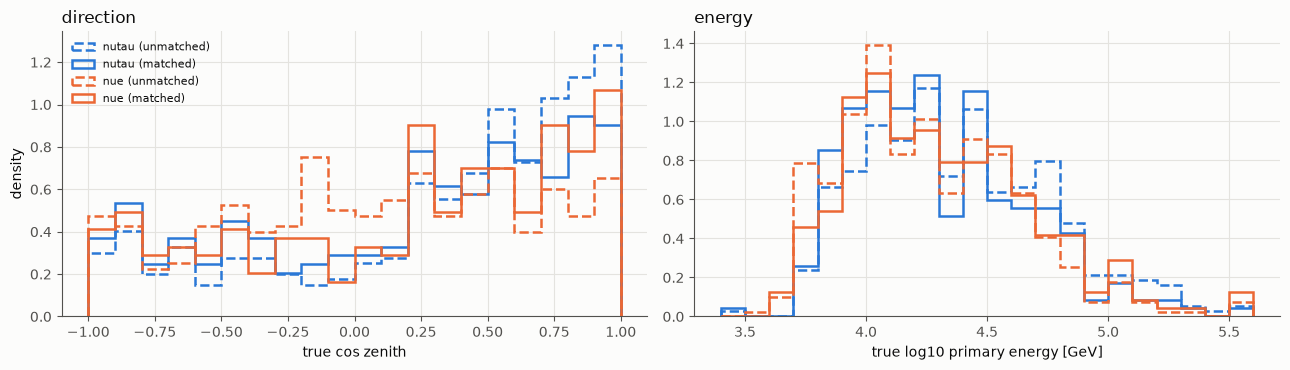

,AUC unmatched,AUC matched,|AUC-0.5| matched
bright_npulses,0.4696,0.4208,0.0792
log_q_total,0.4793,0.4301,0.0699
n_doms,0.4980,0.4335,0.0665
qratio_+3,0.4837,0.4438,0.0562
qratio_+2,0.4873,0.4458,0.0542
resid_+3,0.5654,0.5514,0.0514
dt_+3,0.5656,0.5512,0.0512
near_edge_resid_min,0.4652,0.4497,0.0503
qratio_+1,0.4890,0.4666,0.0334
qratio_-1,0.4688,0.4681,0.0319


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for fl in EVENTS:
    for df, ls, tag in [(SUMMARY_RAW, "--", "unmatched"), (SUMMARY, "-", "matched")]:
        sub = df[df["label"] == LABEL[fl]]
        axes[0].hist(sub["truth_coszen"], bins=np.linspace(-1, 1, 21), histtype="step", density=True,
                     linewidth=1.8, linestyle=ls, color=COL[fl], label=f"{fl} ({tag})")
        axes[1].hist(sub["truth_log_e"], bins=np.linspace(3.4, 5.6, 23), histtype="step", density=True,
                     linewidth=1.8, linestyle=ls, color=COL[fl], label=f"{fl} ({tag})")
axes[0].set_xlabel("true cos zenith"); axes[1].set_xlabel("true log10 primary energy [GeV]")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title("direction", loc="left"); axes[1].set_title("energy", loc="left")
fig.tight_layout(); plt.show()


def single_auc(df):
    out = {}
    for c in df.columns.drop("label"):
        ok = df[c].notna()
        if ok.sum() > 200 and df.loc[ok, "label"].nunique() == 2:
            out[c] = roc_auc_score(df.loc[ok, "label"], df.loc[ok, c])
    return pd.Series(out)


auc_cmp = pd.DataFrame({"AUC unmatched": single_auc(SUMMARY_RAW), "AUC matched": single_auc(SUMMARY)}).round(4)
auc_cmp["|AUC-0.5| matched"] = (auc_cmp["AUC matched"] - 0.5).abs()
display(auc_cmp.sort_values("|AUC-0.5| matched", ascending=False).head(20))

## 4. Sanity checks
* image charge is non-negative and the brightest DOM's row sums to ≤ 1 (= 1 if all its charge is inside the time window);
* how much of the brightest-string charge falls inside `[T_LO, T_HI]` (choose the window so this is ~1);
* how often the brightest DOM is near a string end (missing rows);
* agreement of our brightest DOM's number on its string with reco `brightest_om_brightest_string_id`
  (which is a DOM number 1–60; reco uses all pulses, we apply the 0.1 PE threshold, so ~80% agreement is expected).

flavor,nutau,nue
events,243,243
min pixel,0.0,0.0
centre row sum: median,0.990305,0.988987
centre row sum: max,1.0,1.0
window coverage: median,0.982108,0.981375
window coverage: 5%,0.956452,0.955046
events with missing rows,1.6%,4.9%
brightest dom_no == reco brightest OM,82.3%,83.1%


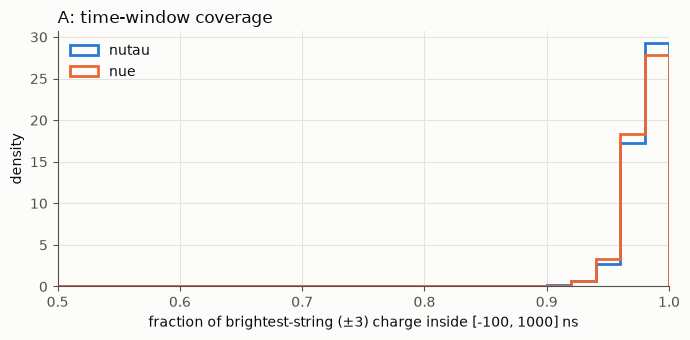

In [6]:
rows = []
for fl, evs in EVENTS.items():
    img = IMGS[fl]
    centre = img[:, N_SIDE, :].sum(axis=1)
    rows.append({
        "flavor": fl, "events": len(evs),
        "min pixel": img.min(), "centre row sum: median": np.median(centre), "centre row sum: max": centre.max(),
        "window coverage: median": np.median(COVER[fl]), "window coverage: 5%": np.percentile(COVER[fl], 5),
        "events with missing rows": f"{(~EXISTS[fl]).any(axis=1).mean():.1%}",
        "brightest dom_no == reco brightest OM": f"{np.mean([ev['dom_no'][ev['b']] == ev['reco_bright_dom_no'] for ev in evs]):.1%}",
    })
display(pd.DataFrame(rows).set_index("flavor").T)
assert all(IMGS[fl].min() >= 0 for fl in IMGS)
assert all((IMGS[fl][:, N_SIDE, :].sum(axis=1) <= 1 + 1e-9).all() for fl in IMGS)

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0.5, 1, 26)
for fl in EVENTS:
    ax.hist(COVER[fl], bins=bins, histtype="step", linewidth=2, color=COL[fl], density=True, label=fl)
ax.set_xlabel(f"fraction of brightest-string (±{N_SIDE}) charge inside [{T_LO:g}, {T_HI:g}] ns")
ax.set_xlim(0.5, 1.0)
ax.set_ylabel("density")
ax.set_title("A: time-window coverage", loc="left")
ax.legend(loc="upper left")
fig.tight_layout(); plt.show()

## 5. Example events (A): brightest-string image and waveforms

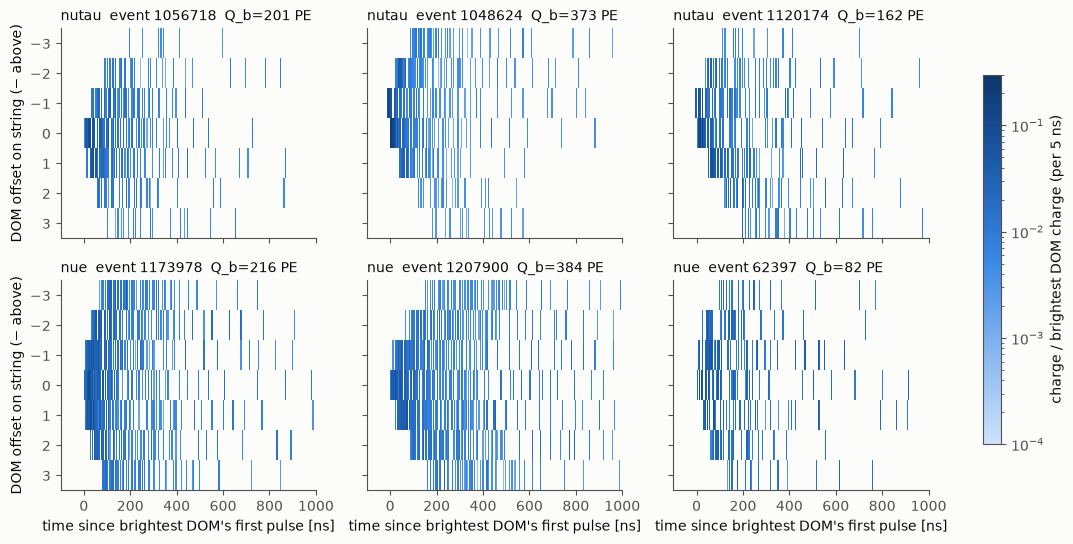

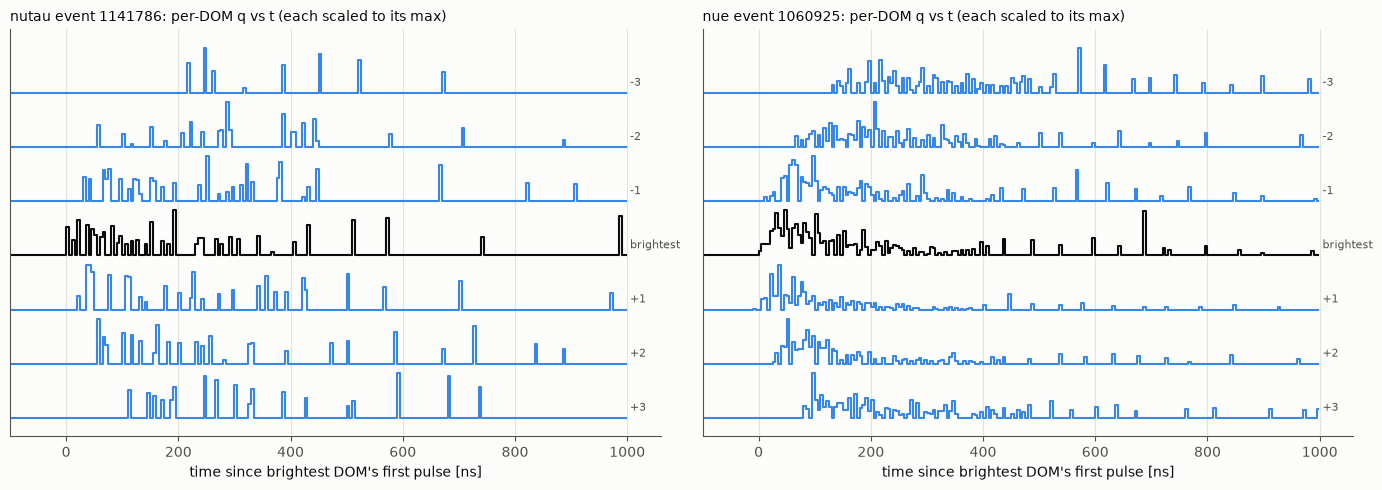

In [7]:
def plot_image(ax, img, title):
    im = ax.imshow(np.ma.masked_less_equal(img, 0), aspect="auto", extent=IMG_EXTENT, cmap=SEQ,
                   norm=LogNorm(vmin=1e-4, vmax=0.3), interpolation="nearest")
    ax.set_yticks(OFFSETS)
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(False)
    return im


rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for r, fl in enumerate(EVENTS):
    for c, i in enumerate(rng.choice(len(EVENTS[fl]), 3, replace=False)):
        ev = EVENTS[fl][i]
        im = plot_image(axes[r, c], IMGS[fl][i],
                        f"{fl}  event {ev['event_no']}  Q_b={ev['q_sum'][ev['b']]:.0f} PE")
for ax in axes[-1]:
    ax.set_xlabel("time since brightest DOM's first pulse [ns]")
for ax in axes[:, 0]:
    ax.set_ylabel("DOM offset on string (− above)")
fig.colorbar(im, ax=axes, label="charge / brightest DOM charge (per 5 ns)", shrink=0.8)
plt.show()


def plot_waveforms(ax, img, exists, title):
    """Stacked q-vs-t traces of the 7 DOMs (each normalised to its own max), top = above."""
    for k, o in enumerate(OFFSETS):
        if not exists[k]:
            continue
        w = img[k] / img[k].max() if img[k].max() > 0 else img[k]
        base = -k * 1.2
        ax.step(BIN_CENTERS, w * 1.0 + base, where="mid", linewidth=1.5,
                color=INK if o == 0 else "#3987e5")
        ax.text(T_HI + 5, base + 0.1, f"{o:+d}" if o else "brightest", fontsize=8, color=INK_2, va="bottom")
    ax.set_yticks([])
    ax.set_xlim(T_LO, T_HI + 60)
    ax.set_title(title, loc="left", fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, fl in zip(axes, EVENTS):
    i = rng.integers(len(EVENTS[fl]))
    plot_waveforms(ax, IMGS[fl][i], EXISTS[fl][i], f"{fl} event {EVENTS[fl][i]['event_no']}: per-DOM q vs t (each scaled to its max)")
    ax.set_xlabel("time since brightest DOM's first pulse [ns]")
fig.tight_layout(); plt.show()

## 6. Mean images and nutau − nue difference (A)
Per-pixel mean over events (rows beyond a string end excluded), and the significance of the difference
`z = (mean_tau − mean_e) / sqrt(var_tau/n_tau + var_e/n_e)`. Structured |z| ≳ 3 regions mean the image carries flavour information
that a CNN could pick up; pure noise looks like salt-and-pepper around 0.

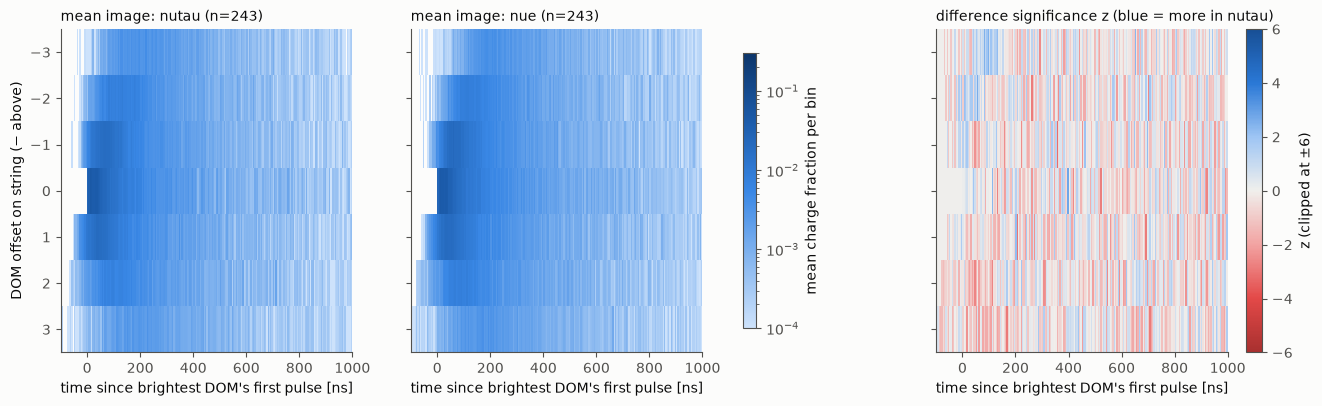

pixels with |z| > 3: 1 of 1540  (≈4.2 expected from noise)


In [8]:
def masked_stats(img, exists):
    w = exists[:, :, None].astype(float)          # [E, R, 1]
    n = w.sum(axis=0)                              # [R, 1]
    mean = (img * w).sum(axis=0) / np.maximum(n, 1)
    var = (((img - mean) ** 2) * w).sum(axis=0) / np.maximum(n - 1, 1)
    return mean, var, n


stats = {fl: masked_stats(IMGS[fl], EXISTS[fl]) for fl in IMGS}
(m1, v1, n1), (m0, v0, n0) = stats["nutau"], stats["nue"]
z = (m1 - m0) / np.sqrt(v1 / n1 + v0 / n0 + 1e-30)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, fl in zip(axes[:2], ["nutau", "nue"]):
    im = plot_image(ax, stats[fl][0], f"mean image: {fl} (n={len(IMGS[fl])})")
    ax.set_xlabel("time since brightest DOM's first pulse [ns]")
fig.colorbar(im, ax=axes[:2], label="mean charge fraction per bin", shrink=0.85)
zim = axes[2].imshow(np.clip(z, -6, 6), aspect="auto", extent=IMG_EXTENT, cmap=DIV,
                     norm=TwoSlopeNorm(0, -6, 6), interpolation="nearest")
axes[2].set_title("difference significance z (blue = more in nutau)", loc="left", fontsize=10)
axes[2].set_xlabel("time since brightest DOM's first pulse [ns]")
axes[2].grid(False)
axes[0].set_ylabel("DOM offset on string (− above)")
fig.colorbar(zim, ax=axes[2], label="z (clipped at ±6)")
plt.show()
print(f"pixels with |z| > 3: {(np.abs(z) > 3).sum()} of {z.size}  (≈{0.0027 * z.size:.1f} expected from noise)")

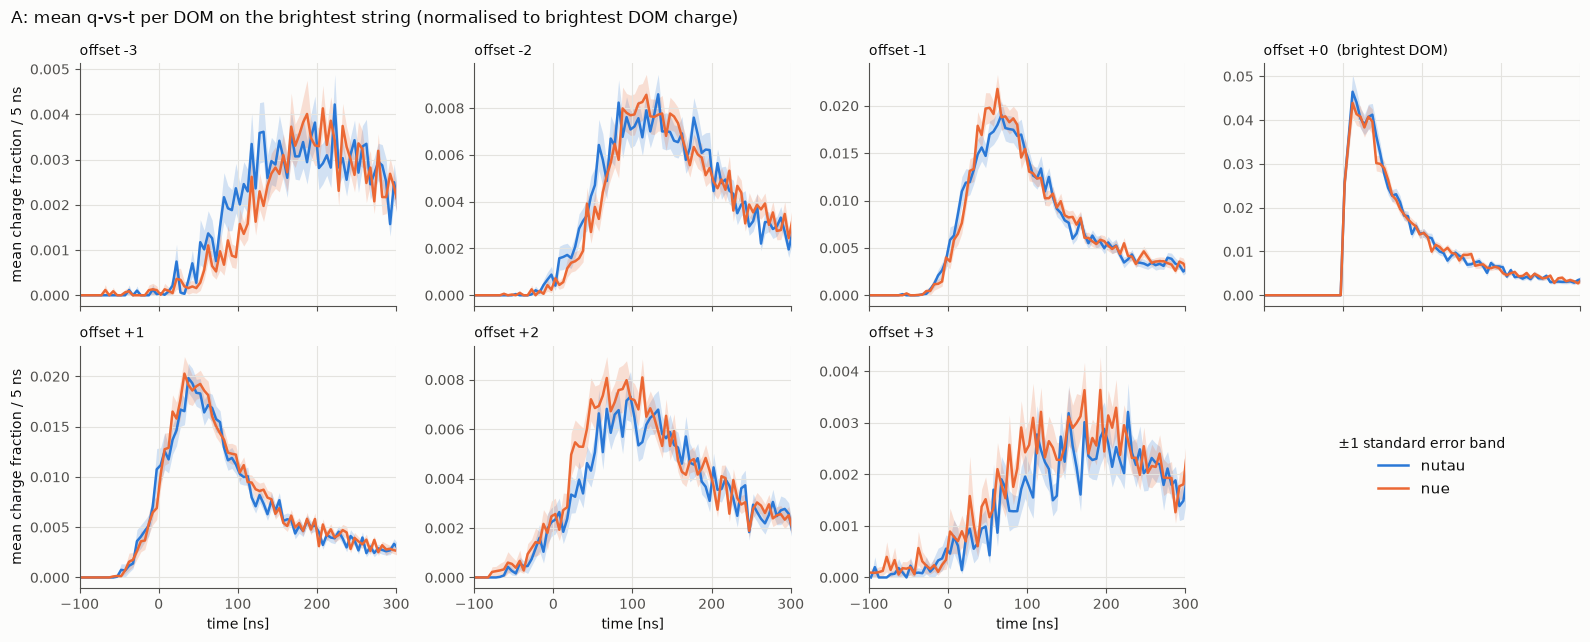

In [9]:
# mean normalised waveform per DOM offset, nutau vs nue (band = ±1 standard error)
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for ax, k in zip(axes.ravel(), range(N_ROWS)):
    for fl, (m, v, n) in stats.items():
        se = np.sqrt(v[k] / n[k])
        ax.plot(BIN_CENTERS, m[k], color=COL[fl], linewidth=1.8, label=fl)
        ax.fill_between(BIN_CENTERS, m[k] - se, m[k] + se, color=COL[fl], alpha=0.2, linewidth=0)
    ax.set_title(f"offset {OFFSETS[k]:+d}" + ("  (brightest DOM)" if OFFSETS[k] == 0 else ""), loc="left", fontsize=10)
    ax.set_xlim(T_LO, 300)
axes.ravel()[-1].legend(*axes[0, 0].get_legend_handles_labels(), loc="center", fontsize=11,
                        title="±1 standard error band")
axes.ravel()[-1].axis("off")
for ax in axes[-1]:
    ax.set_xlabel("time [ns]")
for ax in axes[:, 0]:
    ax.set_ylabel("mean charge fraction / 5 ns")
fig.suptitle("A: mean q-vs-t per DOM on the brightest string (normalised to brightest DOM charge)", x=0.01, ha="left")
fig.tight_layout(); plt.show()

## 7. Neighbour timing and charge relative to the brightest DOM (B)
First-hit time and charge ratio of the same-string neighbours, per offset. A shift between the flavours at fixed offset is the kind
of pattern that brightest-relative node features (and a brightest-DOM readout) would expose to the GAT.

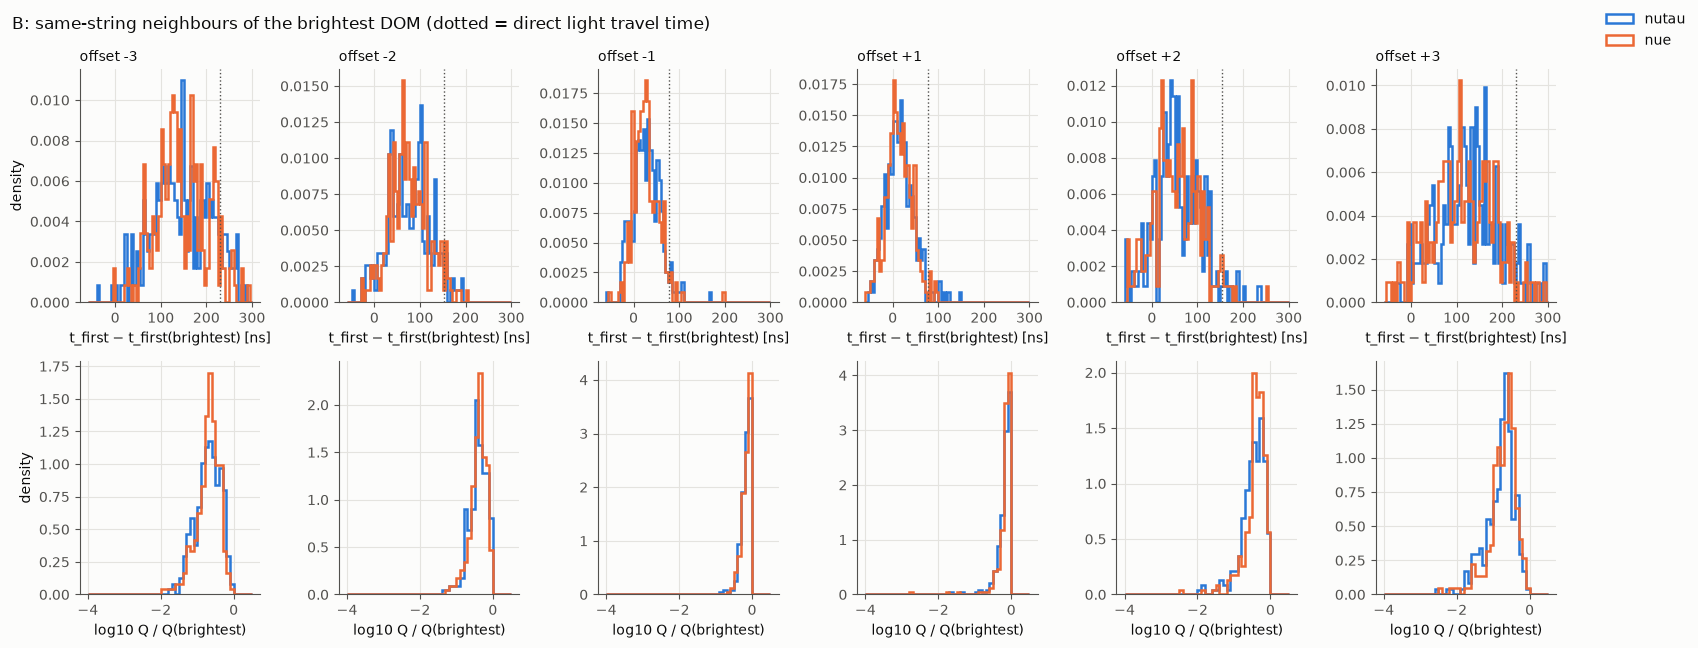

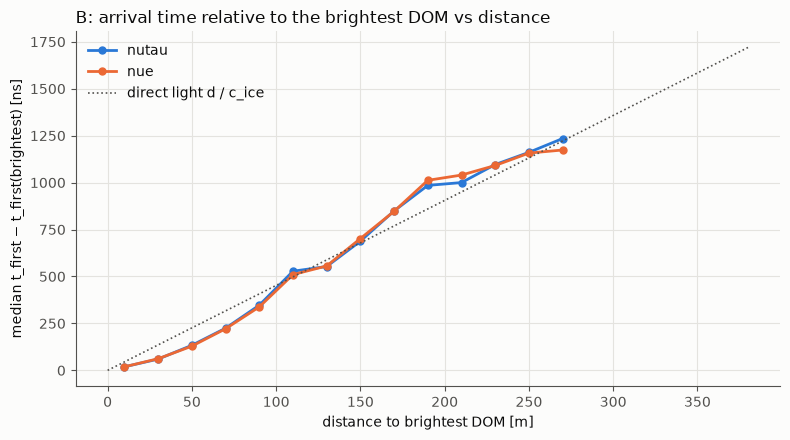

In [10]:
nbr = PER_DOM[(PER_DOM["off"] != 999) & (PER_DOM["off"] != 0)]
fig, axes = plt.subplots(2, 2 * N_SIDE, figsize=(17, 6.5))
for c, o in enumerate([o for o in OFFSETS if o != 0]):
    for fl in EVENTS:
        sub = nbr[(nbr["off"] == o) & (nbr["flavor"] == fl)]
        axes[0, c].hist(sub["dt"], bins=np.linspace(-60, 300, 73), histtype="step", density=True,
                        linewidth=1.8, color=COL[fl], label=fl)
        axes[1, c].hist(np.log10(sub["q_ratio"]), bins=np.linspace(-4, 0.5, 46), histtype="step", density=True,
                        linewidth=1.8, color=COL[fl], label=fl)
    axes[0, c].axvline(abs(o) * 17.0 / C_ICE, color=INK_2, linestyle=":", linewidth=1)   # direct light along string
    axes[0, c].set_title(f"offset {o:+d}", loc="left", fontsize=10)
    axes[0, c].set_xlabel("t_first − t_first(brightest) [ns]")
    axes[1, c].set_xlabel("log10 Q / Q(brightest)")
axes[0, 0].set_ylabel("density"); axes[1, 0].set_ylabel("density")
fig.suptitle("B: same-string neighbours of the brightest DOM (dotted = direct light travel time)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 0.93, 1))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right")
plt.show()

# all DOMs: arrival relative to the brightest vs distance (median per distance bin)
fig, ax = plt.subplots(figsize=(8, 4.5))
dbins = np.arange(0, 400, 20)
for fl in EVENTS:
    sub = PER_DOM[(PER_DOM["flavor"] == fl) & (PER_DOM["d"] > 0)]
    idx = np.digitize(sub["d"], dbins)
    med = [np.median(sub["dt"][idx == i]) if (idx == i).sum() > 30 else np.nan for i in range(1, len(dbins))]
    ax.plot(0.5 * (dbins[1:] + dbins[:-1]), med, "o-", color=COL[fl], label=fl, markersize=5)
ax.plot(dbins, dbins / C_ICE, color=INK_2, linestyle=":", linewidth=1.2, label="direct light d / c_ice")
ax.set_xlabel("distance to brightest DOM [m]")
ax.set_ylabel("median t_first − t_first(brightest) [ns]")
ax.set_title("B: arrival time relative to the brightest DOM vs distance", loc="left")
ax.legend(loc="upper left")
fig.tight_layout(); plt.show()

## 8. Time resolution and causality residuals (C)
The current graph normalises times by 500 ns. Below: how big typical ns-level structure is in those units, and the residuals
`dt − d/c_ice` (per DOM vs brightest) and `|Δt| − d/c_ice` (per k-NN edge) in plain ns.

,value
median pulse spacing on brightest DOM [ns],8.000
in current units (÷500 ns),0.016
in proposed units (÷10 ns),0.800
edge Δt resolution needed (~2 ns) in ÷500 ns units,0.004


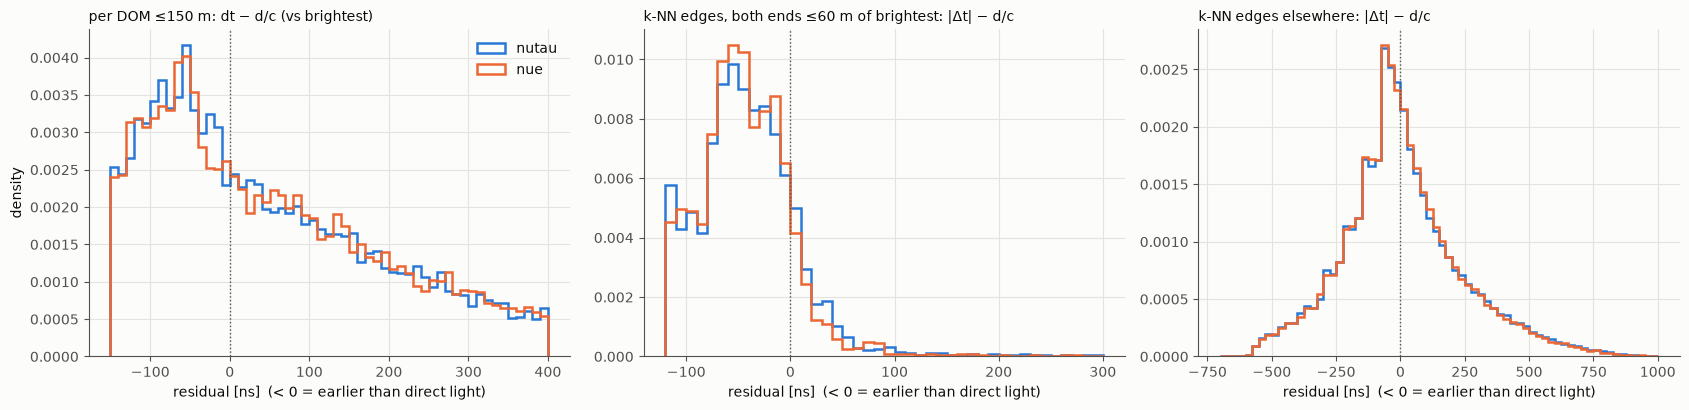

In [11]:
spacing = []
for ev in EVENTS["nutau"][:2000] + EVENTS["nue"][:2000]:
    m = ev["p_dom"] == ev["b"]
    if m.sum() > 1:
        spacing.append(np.diff(ev["p_t"][m]))
spacing = np.concatenate(spacing)
med = np.median(spacing)
display(pd.DataFrame({
    "median pulse spacing on brightest DOM [ns]": [med],
    "in current units (÷500 ns)": [med / 500],
    "in proposed units (÷10 ns)": [med / 10],
    "edge Δt resolution needed (~2 ns) in ÷500 ns units": [2 / 500],
}).T.rename(columns={0: "value"}).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for fl in EVENTS:
    sub = PER_DOM[(PER_DOM["flavor"] == fl) & (PER_DOM["d"] > 0) & (PER_DOM["d"] <= 150)]
    axes[0].hist(sub["resid_b"], bins=np.linspace(-150, 400, 56), histtype="step", density=True,
                 linewidth=1.8, color=COL[fl], label=fl)
    e = EDGES[EDGES["flavor"] == fl]
    axes[1].hist(e["resid_e"][e["near"]], bins=np.linspace(-120, 300, 43), histtype="step", density=True,
                 linewidth=1.8, color=COL[fl], label=fl)
    axes[2].hist(e["resid_e"][~e["near"]], bins=np.linspace(-700, 1000, 69), histtype="step", density=True,
                 linewidth=1.8, color=COL[fl], label=fl)
axes[0].set_title("per DOM ≤150 m: dt − d/c (vs brightest)", loc="left", fontsize=10)
axes[1].set_title(f"k-NN edges, both ends ≤{NEAR_M:g} m of brightest: |Δt| − d/c", loc="left", fontsize=10)
axes[2].set_title("k-NN edges elsewhere: |Δt| − d/c", loc="left", fontsize=10)
for ax in axes:
    ax.axvline(0, color=INK_2, linestyle=":", linewidth=1)
    ax.set_xlabel("residual [ns]  (< 0 = earlier than direct light)")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper right")
fig.tight_layout(); plt.show()

## 9. Quick separability check
Does each input carry nutau/nue information on its own? A gradient-boosted tree (no GNN, 5-fold CV) on:
* **event-level only**: total charge, #DOMs, brightest-DOM charge fraction / rise times (reference: brightness, not the imprint);
* **A**: the flattened brightest-string image;
* **B+C**: per-offset neighbour charge ratio, Δt, causality residual + near-brightest edge residuals;
* **A+B+C**: everything.

Single-feature AUCs are shown first (|AUC − 0.5| ranks how much a feature alone separates). These are *lower bounds* on what the
GAT could extract, but if A or B+C clearly beat event-level only, that input is worth wiring in.

In [12]:
feat_auc = single_auc(SUMMARY.drop(columns=["truth_coszen", "truth_log_e"]))   # truth is not an input
feat_auc = pd.DataFrame({"AUC": feat_auc.round(4), "|AUC-0.5|": (feat_auc - 0.5).abs().round(4)})
display(feat_auc.sort_values("|AUC-0.5|", ascending=False).head(15))

,AUC,|AUC-0.5|
bright_npulses,0.4208,0.0792
log_q_total,0.4301,0.0699
n_doms,0.4335,0.0665
qratio_+3,0.4438,0.0562
qratio_+2,0.4458,0.0542
resid_+3,0.5514,0.0514
dt_+3,0.5512,0.0512
near_edge_resid_min,0.4497,0.0503
qratio_+1,0.4666,0.0334
qratio_-1,0.4681,0.0319


,n features,CV AUC,± (std over folds),time [s]
inputs,,,,
event-level only,6,0.4919,0.0353,1.2
A (image),385,0.5231,0.0630,3.2
B+C,21,0.5573,0.0353,1.1
A+B+C (+event-level),412,0.5404,0.0520,2.9


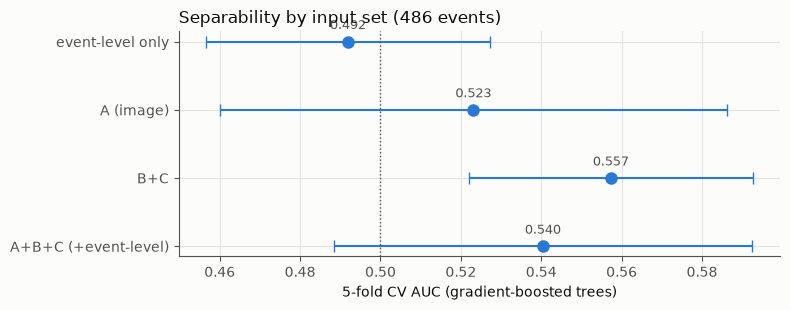

: 

In [ ]:
y = SUMMARY["label"].to_numpy()
img_all = np.concatenate([IMGS["nutau"], IMGS["nue"]])                        # same event order as SUMMARY
nb_c = N_BINS // SEP_COARSEN
img_flat = img_all[:, :, :nb_c * SEP_COARSEN].reshape(len(y), N_ROWS, nb_c, SEP_COARSEN).sum(-1).reshape(len(y), -1)
event_cols = ["log_q_total", "n_doms", "bright_qfrac", "bright_npulses", "bright_rise50", "bright_rise90"]
bc_cols = [c for c in SUMMARY.columns if c.startswith(("qratio_", "dt_", "resid_", "near_"))]
sets = {
    "event-level only": SUMMARY[event_cols].to_numpy(),
    "A (image)": img_flat,
    "B+C": SUMMARY[bc_cols].to_numpy(),
    "A+B+C (+event-level)": np.hstack([img_flat, SUMMARY[bc_cols + event_cols].to_numpy()]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
res = []
for name, X in sets.items():
    t0 = time.time()
    s = cross_val_score(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
                        X, y, cv=cv, scoring="roc_auc")
    res.append({"inputs": name, "n features": X.shape[1], "CV AUC": round(s.mean(), 4), "± (std over folds)": round(s.std(), 4),
                "time [s]": round(time.time() - t0, 1)})
res = pd.DataFrame(res).set_index("inputs")
display(res)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(res["CV AUC"], np.arange(len(res)), xerr=res["± (std over folds)"], fmt="o", color=COL["nutau"],
            markersize=8, capsize=4, linewidth=1.5)
ax.set_yticks(np.arange(len(res)), res.index)
ax.invert_yaxis()
ax.axvline(0.5, color=INK_2, linestyle=":", linewidth=1)
for i, v in enumerate(res["CV AUC"]):
    ax.annotate(f"{v:.3f}", (v, i), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xlabel("5-fold CV AUC (gradient-boosted trees)")
ax.set_title(f"Separability by input set ({len(y)} events)", loc="left")
fig.tight_layout(); plt.show()

## 10. Pulse-level timing and shape without normalising by the DOM total charge
Event features built from individual pulses, kept local in time and in **absolute PE** (no division by a DOM's total charge):

* **`res_` — time relative to a single-cascade expectation, per pulse.** Vertex = charge-weighted centre of the DOMs within
  60 m of the brightest DOM (`VERTEX_SOURCE = "cog"`). **The reco `cascade_vertex_fit_{x,y,z}` is unusable**: its median distance
  to the true interaction vertex (`tau_prod_vertex` / `e_prod_vertex`) is ~540 m, no better than random, while the brightest DOM /
  charge centre is ~48 m away (1k samples). ~48 m ≈ 200 ns of light travel, far coarser than the ~1 ns effect sought, so these
  residuals can only show large-scale timing differences. Vertex time
  $t_0$ = median over the 5 brightest DOMs of $t_\mathrm{first} - d/c_\mathrm{ice}$. Each pulse gets
  $r = t - t_0 - d_\mathrm{DOM}/c_\mathrm{ice}$. Charge (PE) of all pulses on DOMs within 100 m of the vertex in residual windows
  $<-10$, $[-10,10)$, $[10,30)$, $[30,100)$, $\geq100$ ns; late/prompt ratio $[10,30)$ vs $[-10,10)$; median and spread of the
  first-hit residuals of those DOMs. A second, displaced light source would add charge at small positive residuals.
* **`le_` — brightest DOM, absolute charge in windows after its first pulse:** $[0,10)$, $[10,30)$, $[30,100)$, $\geq100$ ns.
* **`thr_` — brightest DOM, time after its first pulse until 1, 3, 10 PE have arrived** (leading edge, independent of the tail).
* **`peak_` — peak structure of the charge-vs-time curve.** `n_peaks` from `check_sqlitenue-val-5TeV.ipynb` (3 ns charge
  histogram, `scipy.signal.find_peaks`, prominence ≥ 15 % of the largest bin) counts *individual unfolded pulses* (isolated
  spikes ~5–8 ns apart with empty bins between them), so it is kept only as `peak_n_brightest_raw`. The other `peak_` features
  first smooth the curve with a Gaussian of σ = `PEAK_SMOOTH_NS` (5 ns, ≈ 1.5 × the 3.3 ns resolution) on a 1 ns grid: number of
  peaks on the brightest DOM, second/first peak height, their time gap, and the fraction of DOMs within 60 m of the brightest DOM
  (≥ 3 pulses) with ≥ 2 peaks.

As in section 9, each feature is tested on the direction/energy-**matched** events (single-feature AUC, distributions) and with a
gradient-boosted tree; the unmatched AUC is shown to flag direction-driven differences.

In [ ]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

VERTEX_SOURCE = "cog"     # "cog": charge-weighted centre near the brightest DOM; "reco": cascade_vertex_fit (unusable, see above)
PEAK_SMOOTH_NS = 5.0      # Gaussian smoothing before peak finding (0 = original 3 ns-histogram definition)

VERTEX = {}
for fl in DBS:
    con = sqlite3.connect(f"file:{DBS[fl]}?mode=ro", uri=True)
    VERTEX[fl] = pd.read_sql_query("SELECT event_no, cascade_vertex_fit_x AS vx, cascade_vertex_fit_y AS vy, "
                                   "cascade_vertex_fit_z AS vz FROM reco", con).set_index("event_no")
    con.close()

RES_EDGES = [-np.inf, -10.0, 10.0, 30.0, 100.0, np.inf]   # ns, residual windows
LE_EDGES = [0.0, 10.0, 30.0, 100.0, np.inf]              # ns after the brightest DOM's first pulse
Q_THRESH = [1.0, 3.0, 10.0]                               # PE
NEAR_VERTEX_M, NEAR_BRIGHT_M = 100.0, 60.0


def n_peaks_info(t_d, q_d, bin_width=3.0, min_prominence_frac=0.15, smooth_ns=0.0):
    """n_peaks() from check_sqlitenue-val-5TeV.ipynb (smooth_ns=0), or on a 1 ns grid smoothed with a Gaussian of
    sigma=smooth_ns. Returns (number of peaks, second/first peak height, gap between them [ns])."""
    if len(t_d) < 3:
        return 1, np.nan, np.nan
    if smooth_ns > 0:
        bin_width = 1.0
        pad = 4 * smooth_ns
        bins = np.arange(t_d.min() - pad, t_d.max() + pad + bin_width, bin_width)
    else:
        bins = np.arange(t_d.min(), t_d.max() + bin_width, bin_width)
    if len(bins) < 2:
        return 1, np.nan, np.nan
    hist, _ = np.histogram(t_d, bins=bins, weights=q_d)
    if smooth_ns > 0:
        hist = gaussian_filter1d(hist.astype(float), smooth_ns / bin_width)
    if hist.max() == 0:
        return 1, np.nan, np.nan
    peaks, _ = find_peaks(hist, prominence=min_prominence_frac * hist.max())
    if len(peaks) < 2:
        return max(len(peaks), 1), 0.0, np.nan
    return len(peaks), hist[peaks[1]] / hist[peaks[0]], (peaks[1] - peaks[0]) * bin_width


def window_label(lo, hi):
    return f"{'' if np.isinf(lo) else int(lo)}..{'' if np.isinf(hi) else int(hi)}"


def pulse_level_features(ev, vtx):
    pos, b, p_dom, p_t, p_q = ev["pos"], ev["b"], ev["p_dom"], ev["p_t"], ev["p_q"]
    row = {}
    # res_: per-pulse residual w.r.t. a point source at the vertex
    if VERTEX_SOURCE == "cog":
        nb_ = np.linalg.norm(pos - pos[b], axis=1) <= NEAR_BRIGHT_M
        vtx = (pos[nb_] * ev["q_sum"][nb_, None]).sum(0) / ev["q_sum"][nb_].sum()
    d_v = np.linalg.norm(pos - vtx, axis=1)
    brightest5 = np.argsort(-ev["q_sum"])[:5]
    t0 = np.median(ev["t_first"][brightest5] - d_v[brightest5] / C_ICE)
    res = p_t - t0 - d_v[p_dom] / C_ICE
    near = d_v[p_dom] <= NEAR_VERTEX_M
    q_res = np.histogram(res[near], bins=RES_EDGES, weights=p_q[near])[0]
    for k, (lo, hi) in enumerate(zip(RES_EDGES[:-1], RES_EDGES[1:])):
        row[f"res_logQ[{window_label(lo, hi)}]ns"] = np.log1p(q_res[k])
    row["res_late_to_prompt"] = np.log((q_res[2] + 1.0) / (q_res[1] + 1.0))
    first_res = (ev["t_first"] - t0 - d_v / C_ICE)[d_v <= NEAR_VERTEX_M]
    row["res_first_hit_median"] = np.median(first_res) if len(first_res) else np.nan
    row["res_first_hit_spread"] = np.std(first_res) if len(first_res) > 1 else np.nan
    # le_ / thr_ / peak_: brightest DOM (pulses are time-ordered within each DOM)
    m = p_dom == b
    t_d, q_d = p_t[m], p_q[m]
    tl = t_d - t_d[0]
    q_le = np.histogram(tl, bins=LE_EDGES, weights=q_d)[0]
    for k, (lo, hi) in enumerate(zip(LE_EDGES[:-1], LE_EDGES[1:])):
        row[f"le_logQ[{window_label(lo, hi)}]ns"] = np.log1p(q_le[k])
    cq = np.cumsum(q_d)
    for thr in Q_THRESH:
        row[f"thr_t_{thr:g}PE_ns"] = tl[np.searchsorted(cq, thr)] if cq[-1] >= thr else np.nan
    row["peak_n_brightest_raw"] = n_peaks_info(t_d, q_d)[0]            # original definition (counts pulses)
    npk, ratio, gap = n_peaks_info(t_d, q_d, smooth_ns=PEAK_SMOOTH_NS)
    row.update(peak_n_brightest=npk, peak_2nd_to_1st=ratio, peak_gap_ns=gap)
    d_b = np.linalg.norm(pos - pos[b], axis=1)
    multi = [n_peaks_info(p_t[p_dom == d], p_q[p_dom == d], smooth_ns=PEAK_SMOOTH_NS)[0] >= 2
             for d in np.flatnonzero((d_b <= NEAR_BRIGHT_M) & (ev["n_pulses"] >= 3))]
    row["peak_frac_multipeak_near"] = np.mean(multi) if multi else np.nan
    return row


def pulse_table(events_by_flavor):
    rows = []
    for fl, evs in events_by_flavor.items():
        V = VERTEX[fl]
        for ev in evs:
            vtx = V.loc[ev["event_no"], ["vx", "vy", "vz"]].to_numpy(float)
            rows.append({"label": ev["label"], **pulse_level_features(ev, vtx)})
    return pd.DataFrame(rows)


t0_ = time.time()
PL = pulse_table(EVENTS)                                   # matched (same event order as SUMMARY)
PL_RAW = pulse_table(EVENTS_RAW) if MATCH_KINEMATICS else PL
print(f"pulse-level features for {len(PL)} matched / {len(PL_RAW)} unmatched events in {time.time() - t0_:.0f} s")
assert (PL["label"].to_numpy() == SUMMARY["label"].to_numpy()).all()

In [ ]:
pl_auc = pd.DataFrame({"AUC unmatched": single_auc(PL_RAW), "AUC matched": single_auc(PL)}).round(4)
pl_auc["|AUC-0.5| matched"] = (pl_auc["AUC matched"] - 0.5).abs()
display(pl_auc.sort_values("|AUC-0.5| matched", ascending=False))

cols = [c for c in PL.columns if c != "label"]
ncol = 4
fig, axes = plt.subplots(int(np.ceil(len(cols) / ncol)), ncol, figsize=(17, 3.0 * np.ceil(len(cols) / ncol)))
for ax, c in zip(axes.ravel(), cols):
    v = PL[c].dropna()
    lo, hi = np.percentile(v, [1, 99]) if len(v) else (0, 1)
    if lo == hi:
        lo, hi = lo - 0.5, hi + 0.5
    bins = np.arange(lo - 0.5, hi + 1.5) if c.startswith("peak_n_brightest") else np.linspace(lo, hi, 31)
    for fl in DBS:
        ax.hist(PL.loc[PL["label"] == LABEL[fl], c].dropna(), bins=bins, histtype="step", density=True,
                linewidth=1.6, color=COL[fl], label=fl)
    ax.set_title(f"{c}  AUC {pl_auc.loc[c, 'AUC matched']:.3f}", loc="left", fontsize=9)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
axes.ravel()[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Pulse-level features, direction/energy matched (title: single-feature AUC)", x=0.01, ha="left")
fig.tight_layout(); plt.show()

In [ ]:
y = SUMMARY["label"].to_numpy()
event_cols = ["log_q_total", "n_doms", "bright_qfrac", "bright_npulses", "bright_rise50", "bright_rise90"]
groups = {g: [c for c in cols if c.startswith(g)] for g in ("res_", "le_", "thr_", "peak_")}
sets = {"event-level only (section 9 reference)": SUMMARY[event_cols].to_numpy(),
        **{f"{g[:-1]} features": PL[c].to_numpy() for g, c in groups.items()},
        "all pulse-level": PL[cols].to_numpy(),
        "all pulse-level + event-level": np.hstack([PL[cols].to_numpy(), SUMMARY[event_cols].to_numpy()])}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
res10 = []
for name, X in sets.items():
    s = cross_val_score(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
                        X, y, cv=cv, scoring="roc_auc")
    res10.append({"inputs": name, "n features": X.shape[1], "CV AUC": round(s.mean(), 4), "±": round(s.std(), 4)})
res10 = pd.DataFrame(res10).set_index("inputs")
display(res10)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(res10["CV AUC"], np.arange(len(res10)), xerr=res10["±"], fmt="o", color=COL["nutau"], markersize=7, capsize=4)
ax.set_yticks(np.arange(len(res10)), res10.index); ax.invert_yaxis()
ax.axvline(0.5, color=INK_2, linestyle=":", linewidth=1)
for i, v in enumerate(res10["CV AUC"]):
    ax.annotate(f"{v:.3f}", (v, i), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xlabel("5-fold CV AUC (gradient-boosted trees, matched events)")
ax.set_title("Separability of the pulse-level feature groups", loc="left")
fig.tight_layout(); plt.show()

## Reading the results
* **Section 4** must pass before trusting anything else (coverage ≈ 1, brightest string mostly matching reco).
* **Section 6** z-map: coherent blue/red structure (e.g. a shifted rise or tail on the ±1, ±2 rows) = an imprint the image branch (A) can learn.
* **Sections 7–8**: per-offset shifts between the flavours = information that B/C features expose to the GAT at ns resolution.
* **Section 9**: if *A* or *B+C* beats *event-level only*, wire that input in; if nothing beats it, the extra inputs mostly re-encode brightness.

Tunables at the top: `N_SIDE`, `T_LO/T_HI/DT_BIN` (A), `NEAR_M`, `C_ICE`, `K_EDGES` (B/C), `N_PER_FLAVOR`.